# 02 — Model Training (Classification and Regression)

**Purpose:** compare Decision Tree, Random Forest, XGBoost and (version 2) an RF + XGBoost average for (A) next-week shortage-risk classification and (B) next-week demand regression. Each family is tuned with **expanding-window time-series cross-validation** inside the development period (train + validation). The final 15% test period is evaluated **once**, after all choices are made.


In [1]:
# CMD: Run this cell first. Makes imports work whether Jupyter starts from the project root or notebooks/.
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Open Jupyter from the Blood-Type-ML project directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
print('Project root:', ROOT)

Project root: d:\Blood-Type-ML


In [2]:
# CMD: Training settings.
from src.config import SEARCH_ITERATIONS, QUICK_SEARCH_ITERATIONS, CV_SPLITS, WALK_FORWARD_STEP, ProjectPaths
N_ITER = SEARCH_ITERATIONS   # random-search candidates per model family (+ the original settings)
PATHS = ProjectPaths.default()
print('Search candidates per family:', N_ITER, '| CV folds:', CV_SPLITS, '| walk-forward retrain every', WALK_FORWARD_STEP, 'weeks')

Search candidates per family: 20 | CV folds: 4 | walk-forward retrain every 4 weeks


## Part 0 — Chronological partitions and time-series CV folds

In [3]:
# CMD: Show the 70/15/15 split by target date and the CV folds inside train+validation.
from src.data_pipeline import load_processed
from src.prediction import chronological_splits, time_series_folds
processed = load_processed()
labeled = processed.dropna(subset=['next_risk', 'target_date'])
parts = chronological_splits(labeled)
summary = pd.DataFrame({name: {'first target': p.target_date.min().date(), 'last target': p.target_date.max().date(),
                               'rows': len(p), **p.next_risk.value_counts().to_dict()} for name, p in parts.items()}).T
display(summary)
folds = time_series_folds(pd.concat([parts['train'], parts['validation']]))
display(pd.DataFrame([{'fold': k, 'train rows': len(t), 'train until': t.target_date.max().date(),
                       'validate from': v.target_date.min().date(), 'validate until': v.target_date.max().date(),
                       'validate rows': len(v)} for k, (t, v) in enumerate(folds)]))

,first target,last target,rows,Medium,Low,High
train,2012-03-26,2020-10-12,1772,757,684,331
validation,2020-10-19,2022-08-15,383,211,123,49
test,2022-08-22,2024-06-17,382,220,120,42


,fold,train rows,train until,validate from,validate until,validate rows
0,0,1289,2018-06-18,2018-06-25,2019-07-01,215
1,1,1504,2019-07-01,2019-07-08,2020-07-13,216
2,2,1720,2020-07-13,2020-07-20,2021-07-26,216
3,3,1936,2021-07-26,2021-08-02,2022-08-15,219


## Part A — Shortage-risk classification
Search space: tree depth, leaf size, number of trees, learning rate, sampling, **and class-weighting strategy** (`none`, `balanced`, `sqrt_balanced`, `balanced_high_boost`). Each family's original settings are always candidate 0, so the search cannot do worse than the original configuration on CV.
Feature set (original / extended / importance-selected) is then chosen by CV. Selection metric: **CV macro-F1**.

In [4]:
# CMD: Train all classifiers, save best_classifier.joblib and classification_*.csv files.
from src.prediction import train_classification
class_results = train_classification(processed, PATHS, n_iter=N_ITER)
cols = ['model', 'selected', 'feature_set', 'weighting', 'train_macro_f1', 'cv_macro_f1', 'validation_macro_f1',
        'validation_wf_macro_f1', 'test_static_accuracy', 'test_accuracy', 'test_macro_f1', 'test_high_recall',
        'high_recall_threshold', 'test_high_recall_mode_high_recall']
display(class_results[cols].round(3))

[classification] train=1772 validation=383 test=382 rows; 4 time-series CV folds; 20 search candidates/family
  Decision Tree best CV macro_f1 = 0.4864 (original settings: 0.4476, 21 candidates)
  Decision Tree feature set chosen: all (61 numeric features)
  Random Forest best CV macro_f1 = 0.5220 (original settings: 0.5030, 21 candidates)
  Random Forest feature set chosen: all (61 numeric features)
  XGBoost       best CV macro_f1 = 0.5217 (original settings: 0.5079, 21 candidates)
  XGBoost       feature set chosen: extended (47 numeric features)
  Ensemble (RF + XGBoost) CV macro_f1 = 0.5138
[classification] selected by CV macro_f1: XGBoost  (445s)


,model,selected,feature_set,weighting,train_macro_f1,cv_macro_f1,validation_macro_f1,validation_wf_macro_f1,test_static_accuracy,test_accuracy,test_macro_f1,test_high_recall,high_recall_threshold,test_high_recall_mode_high_recall
0,XGBoost,True,extended,sqrt_balanced,0.909,0.522,0.540,0.548,0.589,0.563,0.426,0.143,0.175,0.500
1,Random Forest,False,all,balanced,0.953,0.522,0.562,0.547,0.584,0.552,0.449,0.214,0.250,0.524
2,Ensemble (RF + XGBoost),False,union of members,balanced+sqrt_balanced,0.933,0.514,0.545,0.537,0.597,0.560,0.435,0.167,0.225,0.476
3,Decision Tree,False,all,none,0.670,0.486,0.498,0.527,0.552,0.605,0.460,0.167,0.125,0.643


In [5]:
# CMD: Hyper-parameter search log - top 5 candidates per family (CV scores only).
search = pd.read_csv(PATHS.result('classification_hyperparameter_search.csv'))
display(search.sort_values('cv_macro_f1', ascending=False).groupby('family').head(5)
        [['family', 'is_original_settings', 'weighting', 'params', 'cv_accuracy', 'cv_macro_f1', 'cv_high_recall']].round(3))

,family,is_original_settings,weighting,params,cv_accuracy,cv_macro_f1,cv_high_recall
21,Random Forest,False,balanced,"{""n_estimators"": 300, ""min_samples_leaf"": 2, ""...",0.584,0.522,0.430
42,XGBoost,False,sqrt_balanced,"{""subsample"": 0.7, ""reg_lambda"": 5.0, ""n_estim...",0.590,0.522,0.365
22,Random Forest,False,sqrt_balanced,"{""n_estimators"": 300, ""min_samples_leaf"": 2, ""...",0.588,0.515,0.376
23,Random Forest,False,balanced,"{""n_estimators"": 300, ""min_samples_leaf"": 4, ""...",0.570,0.514,0.463
24,Random Forest,False,balanced,"{""n_estimators"": 500, ""min_samples_leaf"": 4, ""...",0.573,0.514,0.463
25,Random Forest,False,balanced,"{""n_estimators"": 500, ""min_samples_leaf"": 2, ""...",0.576,0.514,0.428
43,XGBoost,False,none,"{""subsample"": 0.7, ""reg_lambda"": 5.0, ""n_estim...",0.595,0.512,0.303
44,XGBoost,False,balanced,"{""subsample"": 0.8, ""reg_lambda"": 1.0, ""n_estim...",0.567,0.510,0.491
45,XGBoost,False,balanced_high_boost,"{""subsample"": 0.9, ""reg_lambda"": 1.0, ""n_estim...",0.560,0.509,0.425
46,XGBoost,True,balanced,"{""n_estimators"": 130, ""max_depth"": 4, ""learnin...",0.568,0.508,0.409


In [6]:
# CMD: Class-imbalance investigation - best CV macro-F1 and High recall for each weighting strategy.
display(search.groupby(['family', 'weighting'])[['cv_macro_f1', 'cv_high_recall']].max().unstack('weighting').round(3))

cv_macro_f1                                          cv_high_recall                                         
weighting        balanced balanced_high_boost   none sqrt_balanced       balanced balanced_high_boost   none sqrt_balanced
family                                                                                                                    
Decision Tree       0.478               0.469  0.486         0.476          0.507               0.572  0.405         0.444
Random Forest       0.522               0.509  0.505         0.515          0.494               0.602  0.294         0.376
XGBoost             0.510               0.509  0.512         0.522          0.562               0.574  0.315         0.374

,family,feature_set,n_features,cv_macro_f1
0,Decision Tree,all,61,0.4864
1,Decision Tree,original,34,0.4238
2,Decision Tree,extended,47,0.4245
3,Decision Tree,selected,10,0.4318
4,Decision Tree,all_external,89,0.4071
5,Random Forest,all,61,0.5220
6,Random Forest,original,34,0.4972
7,Random Forest,extended,47,0.5126
8,Random Forest,selected,17,0.5032
9,Random Forest,all_external,89,0.5124


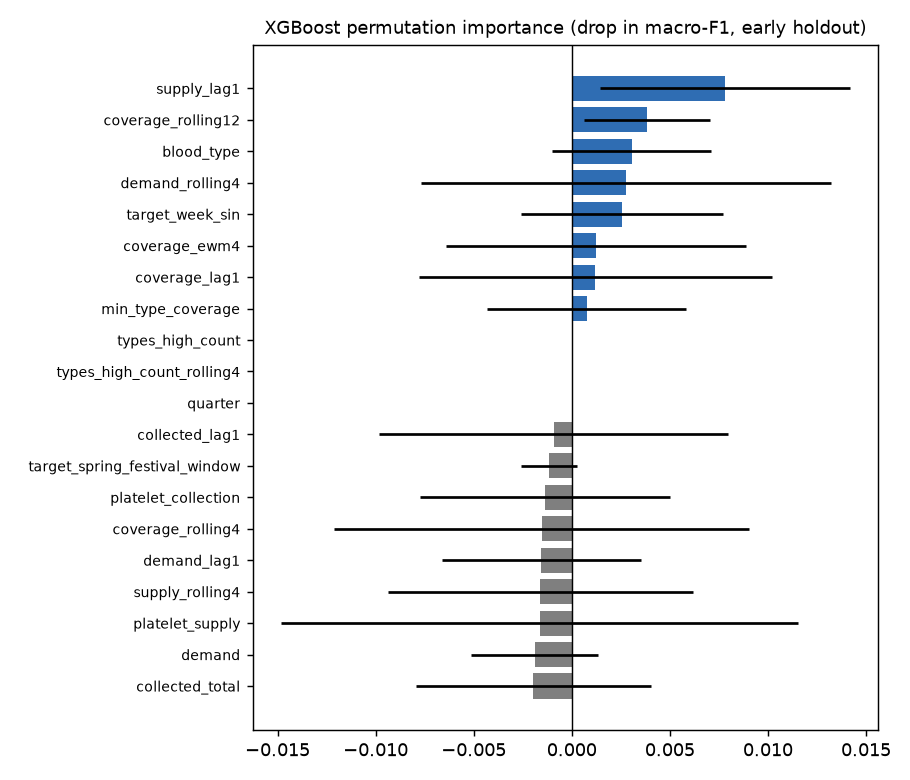

In [7]:
# CMD: Feature-set comparison and permutation importance of the selected classifier.
display(pd.read_csv(PATHS.result('classification_feature_set_trials.csv')).round(4))
from IPython.display import Image
display(Image(filename=str(PATHS.figures_dir / 'feature_importance_classification.png')))

## Part B — Next-week demand regression
Search space includes the XGBoost loss (`squarederror` vs `absoluteerror`). Selection metric: **CV MAE**.

In [8]:
# CMD: Train regressors and save best_regressor.joblib and regression_*.csv files.
from src.prediction import train_regression
reg_results = train_regression(processed, PATHS, n_iter=N_ITER)
display(reg_results[['model', 'selected', 'feature_set', 'train_mae', 'cv_mae', 'validation_mae', 'validation_wf_mae',
                     'test_static_mae', 'test_mae', 'test_rmse', 'test_mape_percent']].round(2))

[regression] train=1774 validation=383 test=384 rows; 4 time-series CV folds; 20 search candidates/family
  Decision Tree best CV mae = 136.1096 (original settings: 146.9444, 21 candidates)
  Decision Tree feature set chosen: all (61 numeric features)
  Random Forest best CV mae = 122.9696 (original settings: 123.8120, 21 candidates)
  Random Forest feature set chosen: all_external (89 numeric features)
  XGBoost       best CV mae = 120.1200 (original settings: 120.1895, 21 candidates)
  XGBoost       feature set chosen: all_external (89 numeric features)
  Ensemble (RF + XGBoost) CV mae = 119.7577
[regression] selected by CV mae: XGBoost  (733s)


,model,selected,feature_set,train_mae,cv_mae,validation_mae,validation_wf_mae,test_static_mae,test_mae,test_rmse,test_mape_percent
0,XGBoost,True,all_external,54.52,119.37,126.95,119.33,169.49,170.35,235.39,15.34
1,Ensemble (RF + XGBoost),False,union of members,43.19,119.76,127.40,119.64,170.30,169.02,235.59,15.23
2,Random Forest,False,all_external,32.88,121.99,129.91,122.16,172.82,169.40,238.41,15.26
3,Decision Tree,False,all,96.90,136.11,140.24,131.42,187.10,191.39,262.16,16.76


,family,is_original_settings,params,cv_mae,cv_rmse
42,XGBoost,False,"{""subsample"": 0.7, ""objective"": ""reg:squareder...",120.12,166.16
43,XGBoost,True,"{""n_estimators"": 130, ""max_depth"": 4, ""learnin...",120.19,166.40
44,XGBoost,False,"{""subsample"": 0.7, ""objective"": ""reg:squareder...",120.32,166.46
21,Random Forest,False,"{""n_estimators"": 300, ""min_samples_leaf"": 1, ""...",122.97,171.24
22,Random Forest,False,"{""n_estimators"": 500, ""min_samples_leaf"": 3, ""...",123.20,172.50
23,Random Forest,False,"{""n_estimators"": 150, ""min_samples_leaf"": 3, ""...",123.31,171.90
0,Decision Tree,False,"{""min_samples_leaf"": 8, ""max_features"": 0.5, ""...",136.11,188.98
1,Decision Tree,False,"{""min_samples_leaf"": 4, ""max_features"": null, ...",137.96,191.64
2,Decision Tree,False,"{""min_samples_leaf"": 32, ""max_features"": 0.5, ...",139.26,191.54


,family,feature_set,n_features,cv_mae
0,Decision Tree,all,61,136.11
1,Decision Tree,original,34,138.57
2,Decision Tree,extended,47,143.45
3,Decision Tree,selected,12,139.19
4,Decision Tree,all_external,89,140.70
5,Random Forest,all,61,122.97
6,Random Forest,original,34,123.60
7,Random Forest,extended,47,123.30
8,Random Forest,selected,44,122.08
9,Random Forest,all_external,89,121.99


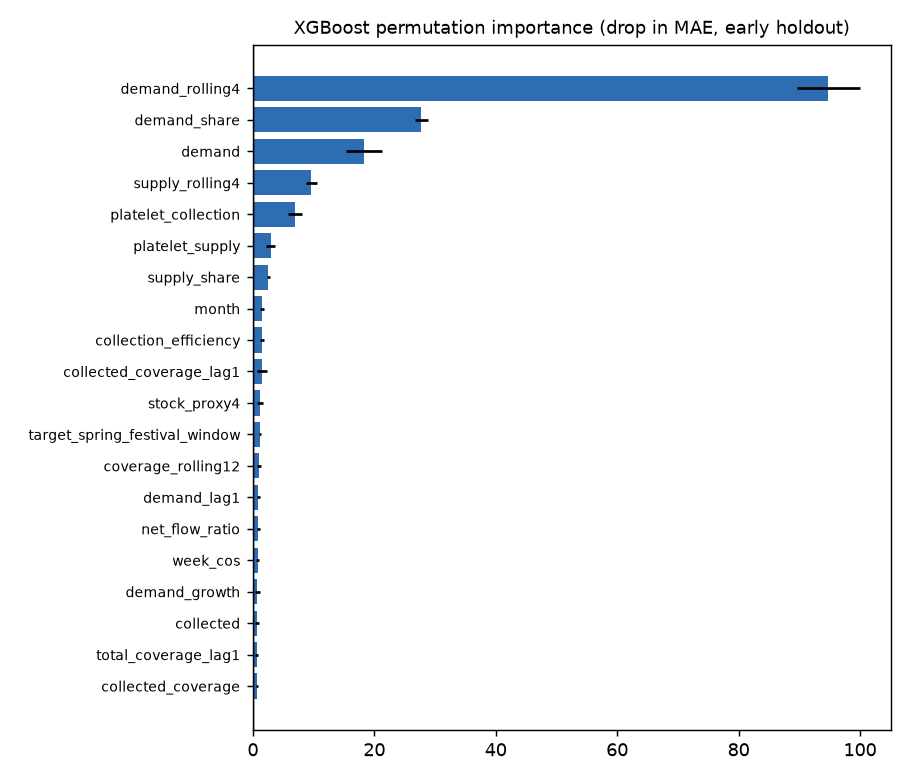

In [9]:
# CMD: Regression search log and feature-set comparison.
rsearch = pd.read_csv(PATHS.result('regression_hyperparameter_search.csv'))
display(rsearch.sort_values('cv_mae').groupby('family').head(3)[['family', 'is_original_settings', 'params', 'cv_mae', 'cv_rmse']].round(2))
display(pd.read_csv(PATHS.result('regression_feature_set_trials.csv')).round(2))
display(Image(filename=str(PATHS.figures_dir / 'feature_importance_regression.png')))

In [10]:
# CMD: Save the next-week forecast and the summary report (same as run_pipeline.py step 4).
from run_pipeline import write_report
from src.prediction import predict_next_week
forecast = predict_next_week(processed, PATHS)
forecast.to_csv(PATHS.result('next_week_forecast.csv'), index=False)
_ = write_report(PATHS, class_results, reg_results, forecast, N_ITER, 0)
print('Saved', PATHS.result('summary_report.md'))

Saved D:\Blood-Type-ML\results\summary_report.md
